### Import Library

In [10]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.inspection import permutation_importance
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

### Memuat data siap pakai dari hasil Tahap 6

In [2]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Mencari Kernel Terbaik untuk SVR Berdasarkan R2 Score

In [5]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
r2_scores = []

for k in kernels:
    # TransformedTargetRegressor otomatis menyesuaikan skala miliaran Rupiah saat SVR belajar
    svr_temp = TransformedTargetRegressor(
        regressor=SVR(kernel=k),
        transformer=StandardScaler()
    )
    svr_temp.fit(X_train, y_train)
    y_pred_temp = svr_temp.predict(X_test)
    r2_scores.append(r2_score(y_test, y_pred_temp))

best_kernel = kernels[np.argmax(r2_scores)]
print(f"Kernel terbaik adalah: {best_kernel} dengan R2 Score: {max(r2_scores):.4f}")

Kernel terbaik adalah: rbf dengan R2 Score: 0.6639


### Melatih Model SVM Regres Final

In [6]:
start_time = time.perf_counter()

model_svm = TransformedTargetRegressor(
    regressor=SVR(kernel=best_kernel),
    transformer=StandardScaler()
)
model_svm.fit(X_train, y_train)
y_pred = model_svm.predict(X_test)

end_time = time.perf_counter()

waktu_svm = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model SVM Regresi: {waktu_svm:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model SVM Regresi: 1.3077 detik


### Evaluasi

In [7]:
r2_svm   = r2_score(y_test, y_pred)
mae_svm  = mean_absolute_error(y_test, y_pred)
rmse_svm = np.sqrt(mean_squared_error(y_test, y_pred))
mape_svm = mean_absolute_percentage_error(y_test, y_pred) * 100 # Dalam persen (%)

print("=== HASIL EVALUASI MODEL SVM REGRESI ===")
print(f"1. R2 Score       : {r2_svm:.4f} ({r2_svm*100:.2f}%)")
print(f"2. MAE            : Rp {mae_svm:,.2f}")
print(f"3. RMSE           : Rp {rmse_svm:,.2f}")
print(f"4. MAPE           : {mape_svm:.2f}%")
print(f"5. Waktu Eksekusi : {waktu_svm:.4f} detik")

=== HASIL EVALUASI MODEL SVM REGRESI ===
1. R2 Score       : 0.6639 (66.39%)
2. MAE            : Rp 556,538,792.32
3. RMSE           : Rp 759,431,406.35
4. MAPE           : 183.97%
5. Waktu Eksekusi : 1.3077 detik


### Tabel Perbandingan Harga Aktual dan Harga Prediksi

In [8]:
df_perbandingan_harga = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred
})

display(df_perbandingan_harga.head(10))

,Aktual,Prediksi
0,2400000000,1.937976e+09
1,3400000000,2.619407e+09
2,2270000000,2.481840e+09
3,2480000000,3.233456e+09
4,1400000000,1.670035e+09
5,1350000000,1.918676e+09
6,4600000000,3.783877e+09
7,1600000000,1.444180e+09
8,2100000000,4.329648e+09
9,2200000000,2.951085e+09


### Visualisasi Perbandingan Harga Aktual dan Prediksi

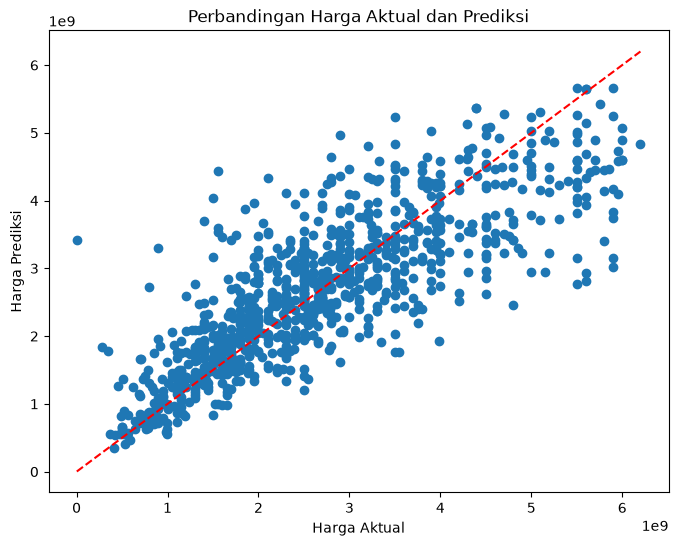

In [9]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Perbandingan Harga Aktual dan Prediksi')

plt.show()

### Analisis Feature Importance pada SVM Regresi

In [11]:
# Mengambil nama kolom fitur dari step 5
df_step5 = joblib.load('../dataset/step_05_selected.pkl')
X_columns = df_step5.drop(columns=['price']).columns

# Menghitung tingkat kepentingan fitur (importance) pada model SVM
perm_importance = permutation_importance(model_svm, X_test, y_test, n_repeats=5, random_state=42)

feature_importance = pd.DataFrame({
    'Fitur': X_columns,
    'Importance': perm_importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Fitur,Importance
11,total_area,0.156348
6,building_area,0.130297
5,land_area,0.128502
1,city,0.063444
3,bath_rooms,0.061547
0,district,0.042984
10,total_facilities,0.031675
7,total_rooms,0.028314
9,remaining_land,0.028041
2,bed_rooms,0.022987


### Menyimpan Hasil SVM Regresi

In [12]:
hasil_svm_reg = {
    'Model': 'SVM',
    'R2': r2_svm,
    'MAE': mae_svm,
    'RMSE': rmse_svm,
    'MAPE (%)': mape_svm,
    'Waktu (Detik)': waktu_svm,
    'y_test': y_test,
    'y_pred': y_pred
}

joblib.dump(hasil_svm_reg, 'hasil_svm.pkl')
print("Hasil evaluasi SVM Regresi berhasil disimpan ke 'regresi_model/hasil_svm.pkl'!")

Hasil evaluasi SVM Regresi berhasil disimpan ke 'regresi_model/hasil_svm.pkl'!
